In [1]:
\
import mne
import numpy as np
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import matplotlib.transforms as transforms
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

dataset_path = Path('../Infants_data')
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]


In [2]:
\
# Hardcoded edge order (F, C, T, P, O pairs)
edge_labels = [
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ', 'Fp2-F3',
    'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ', 'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ', 'F7-F8', 'F7-FZ', 'F8-FZ', 'Fp1-C3', 'Fp1-C4',
    'Fp1-CZ', 'Fp2-C3', 'Fp2-C4', 'Fp2-CZ', 'F3-C3', 'F3-C4', 'F3-CZ', 'F4-C3',
    'F4-C4', 'F4-CZ', 'F7-C3', 'F7-C4', 'F7-CZ', 'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ', 'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6', 'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6', 'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6', 'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ', 'Fp2-P3', 'Fp2-P4', 'Fp2-PZ', 'F3-P3',
    'F3-P4', 'F3-PZ', 'F4-P3', 'F4-P4', 'F4-PZ', 'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ', 'FZ-P3', 'FZ-P4', 'FZ-PZ', 'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2', 'F3-O1', 'F3-O2', 'F4-O1', 'F4-O2', 'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2', 'FZ-O1', 'FZ-O2', 'C3-C4', 'C3-CZ', 'C4-CZ', 'C3-T3',
    'C3-T4', 'C3-T5', 'C3-T6', 'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6', 'CZ-T3',
    'CZ-T4', 'CZ-T5', 'CZ-T6', 'C3-P3', 'C3-P4', 'C3-PZ', 'C4-P3', 'C4-P4',
    'C4-PZ', 'CZ-P3', 'CZ-P4', 'CZ-PZ', 'C3-O1', 'C3-O2', 'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2', 'T3-T4', 'T3-T5', 'T3-T6', 'T4-T5', 'T4-T6', 'T5-T6',
    'T3-P3', 'T3-P4', 'T3-PZ', 'T4-P3', 'T4-P4', 'T4-PZ', 'T5-P3', 'T5-P4',
    'T5-PZ', 'T6-P3', 'T6-P4', 'T6-PZ', 'T3-O1', 'T3-O2', 'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2', 'T6-O1', 'T6-O2', 'P3-P4', 'P3-PZ', 'P4-PZ', 'P3-O1',
    'P3-O2', 'P4-O1', 'P4-O2', 'PZ-O1', 'PZ-O2', 'O1-O2',
]

def detect_bad_channels(raw, flat_threshold=1e-12, noise_threshold=1e-2):
    data = raw.get_data()
    channel_names = raw.ch_names
    bad_refs = {'PG1', 'PG2', 'REF', 'GND', 'GROUND', '25+', '26+', '27+'}
    stds = np.std(data, axis=1)
    ranges = np.ptp(data, axis=1)
    return [
        ch for ch, s, r in zip(channel_names, stds, ranges)
        if s < flat_threshold or s > noise_threshold or r == 0 or ch.upper() in bad_refs
    ]

def load_annotations(subject_id, session_id, dataset_path):
    annotations_path = (
        dataset_path / 'derivatives' / 'NeuronicEEG' / subject_id /
        session_id / 'eeg' / f'{subject_id}_{session_id}_task-EEG_annotations.tsv'
    )
    if not annotations_path.exists():
        return None
    rows = []
    for line in annotations_path.read_text().splitlines()[1:]:
        fields = [f.strip() for f in line.split('\t')]
        if len(fields) >= 2 and fields[0] and fields[1]:
            try:
                rows.append([float(fields[0]), float(fields[1]), fields[2] if len(fields) > 2 and fields[2] else 'eyes_closed'])
            except ValueError:
                pass
    return pd.DataFrame(rows, columns=['onset', 'duration', 'label']) if rows else None

def segment_data_from_annotations(raw, annotations_df, label='eyes_closed'):
    sfreq = raw.info['sfreq']
    data = raw.get_data()
    n_samples = data.shape[1]
    label_lower = label.lower().strip()
    ann_labels = annotations_df['label'].fillna('').astype(str).str.lower().str.strip()
    
    if label_lower == 'eyes_closed':
        mask = ann_labels.isin(['eyes_closed', 'ojos_cerrados'])
    else:
        mask = ann_labels == label_lower
        
    segments = []
    for _, row in annotations_df[mask].iterrows():
        start = int(row['onset'] * sfreq)
        end = int((row['onset'] + row['duration']) * sfreq)
        if 0 <= start <= end <= n_samples:
            segments.append(data[:, start:end])
    return segments


In [3]:
\
# Extract segments, filter in delta band (0.5-4 Hz), compute correlation matrices
n_segments = 12
subject_matrices = {}
subject_segments = {}

for subj in formatted_subjects:
    subject_path = dataset_path / subj
    edf_files = sorted(subject_path.rglob('*.edf'))
    if not edf_files:
        print(f'Skipping {subj}: no EDF files found')
        continue

    # Process ses-1 only
    edf_path = next((p for p in edf_files if 'ses-1' in p.stem), None)
    if not edf_path:
        continue
        
    session_id = 'ses-1'
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
    
    bad_channels = detect_bad_channels(raw)
    raw_clean = raw.copy()
    if bad_channels:
        raw_clean.drop_channels(bad_channels)
        
    # Apply bandpass filter for Delta band (0.5 - 4 Hz)
    raw_clean.filter(l_freq=0.5, h_freq=4.0, fir_design='firwin', verbose=False)
    
    annotations_df = load_annotations(subj, session_id, dataset_path)
    if annotations_df is None:
        continue
        
    segments = segment_data_from_annotations(raw_clean, annotations_df, label='eyes_closed')
    if not segments:
        continue
        
    channel_labels = raw_clean.ch_names
    matrices = []
    seg_list = []
    
    for segment in segments[:n_segments]:
        corr_matrix = np.corrcoef(segment)
        abs_matrix = np.abs(corr_matrix)
        matrices.append(abs_matrix)
        
        df = pd.DataFrame(abs_matrix, index=channel_labels, columns=channel_labels)
        # Handle cases where some edges might have dropped channels
        try:
            edge_vals = [df.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
            seg_list.append(np.array(edge_vals))
        except KeyError:
            # If a required channel was dropped, skip this subject entirely or handle appropriately
            seg_list = []
            break
            
    if matrices and seg_list and len(seg_list) == len(segments[:n_segments]):
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=channel_labels, columns=channel_labels)
        subject_segments[subj] = seg_list

print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


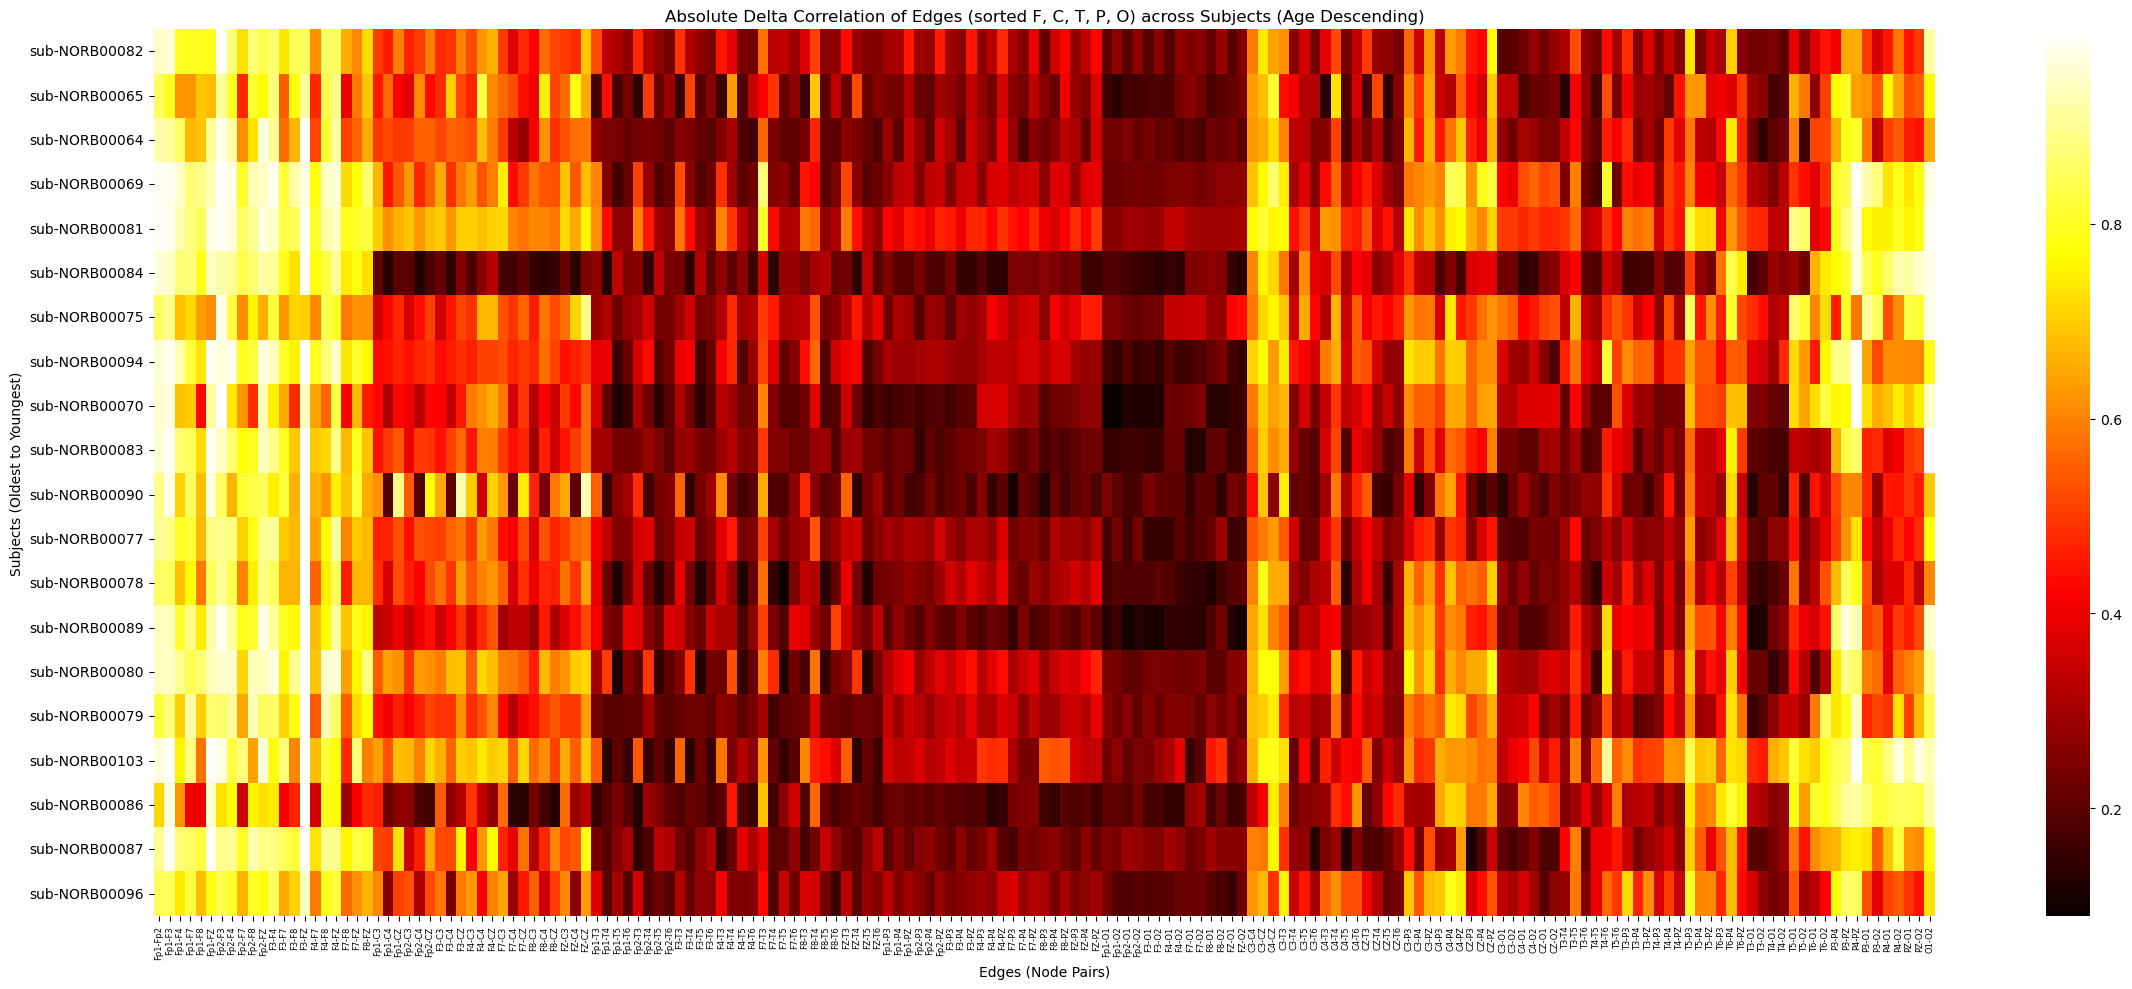

In [4]:
\
# Load ages and sort subjects descending (oldest top, youngest bottom)
ages_df = pd.read_csv('../age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_matrices:
        df_matrix = subject_matrices[subj]
        row_data = [df_matrix.loc[e.split('-')[0], e.split('-')[1]] for e in edge_labels]
        heatmap_data.append(row_data)
        valid_subjects.append(subj)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(24, 10))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Absolute Delta Correlation of Edges (sorted F, C, T, P, O) across Subjects (Age Descending)')
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subjects (Oldest to Youngest)')
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()


In [5]:
\
# Calculate edge-wise Jaccard index for all subject pairs (20C2)
subject_pairs = list(combinations(valid_subjects, 2))
pair_edgewise_jaccard = {}

for subj1, subj2 in subject_pairs:
    segment_edge_jaccards = []
    
    # We use the minimum length of segments available between the pair, capped at 12
    n_segs = min(len(subject_segments[subj1]), len(subject_segments[subj2]))
    
    for k in range(n_segs):
        u = subject_segments[subj1][k]  
        v = subject_segments[subj2][k]
        
        mins = np.minimum(u, v)
        maxs = np.maximum(u, v)
        
        with np.errstate(divide='ignore', invalid='ignore'):
            j_score = np.where(maxs != 0, mins / maxs, 0)
            
        segment_edge_jaccards.append(j_score)
        
    pair_edgewise_jaccard[(subj1, subj2)] = np.mean(segment_edge_jaccards, axis=0)

print(f"Calculated edge-wise Jaccard indices for {len(pair_edgewise_jaccard)} subject pairs.")


Calculated edge-wise Jaccard indices for 190 subject pairs.


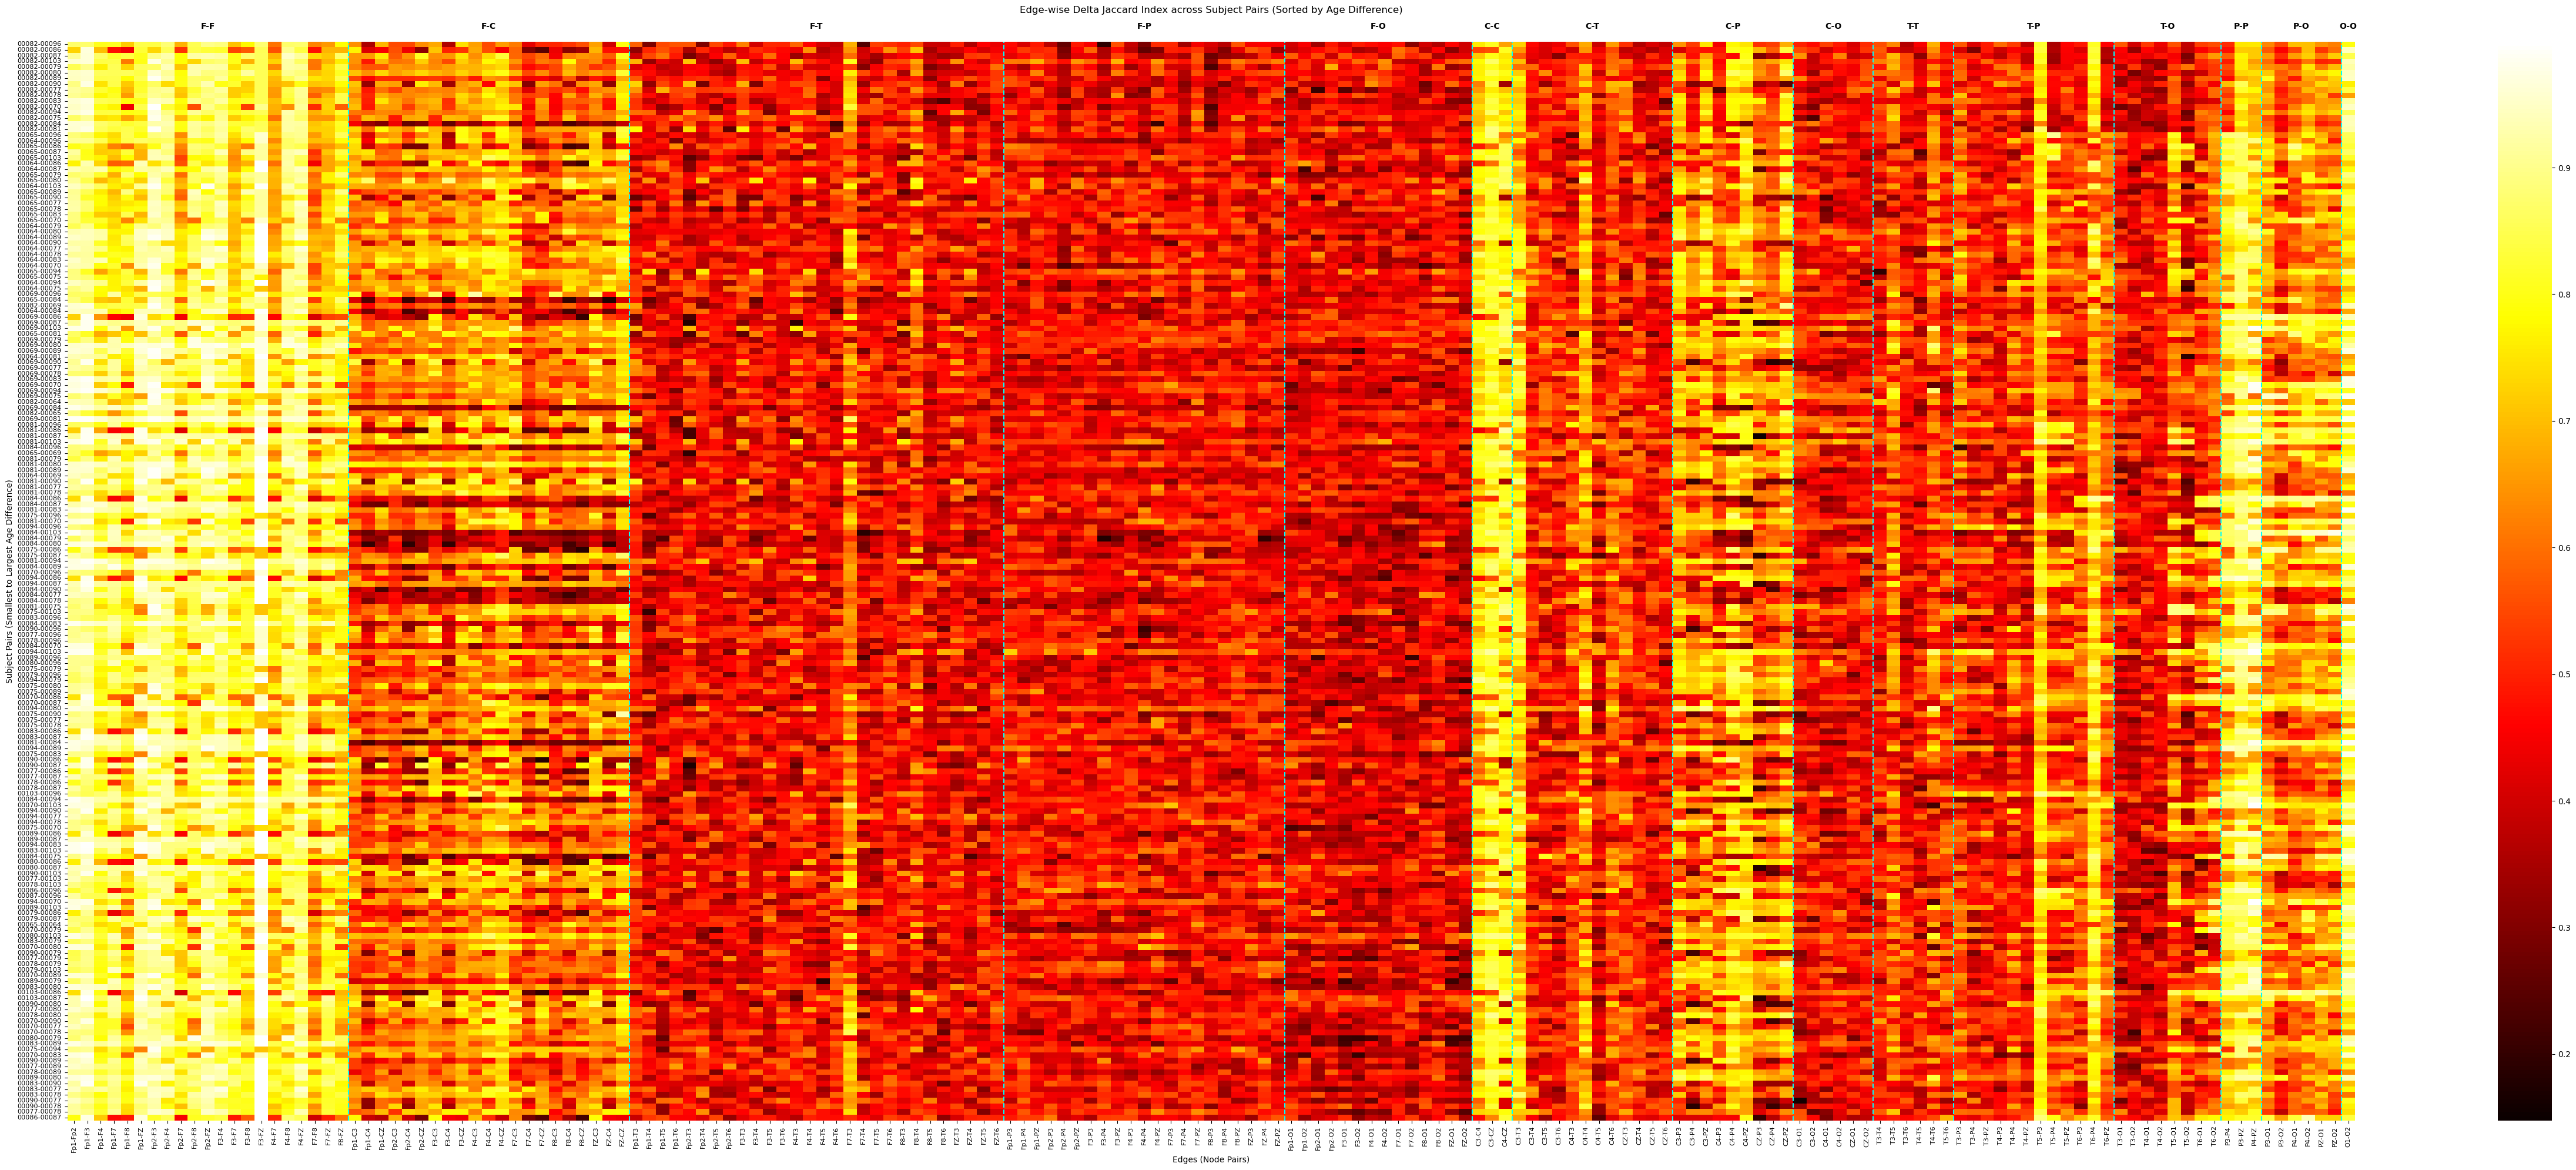

In [6]:
\
# Create a dictionary mapping subject ID to their age
age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Compute absolute age differences for each subject pair
pair_age_diffs = {}
for subj1, subj2 in subject_pairs:
    diff = abs(age_dict[subj1] - age_dict[subj2])
    pair_age_diffs[(subj1, subj2)] = diff

# Sort subject pairs by age difference (descending: largest difference at top, smallest at bottom)
sorted_pairs = sorted(pair_age_diffs.keys(), key=lambda p: pair_age_diffs[p], reverse=True)

# Prepare data for heatmap
heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    heatmap_data.append(pair_edgewise_jaccard[pair])
    s1 = pair[0].replace('sub-NORB', '')
    s2 = pair[1].replace('sub-NORB', '')
    yticklabels.append(f"{s1}-{s2}")

heatmap_data = np.array(heatmap_data)

# Plot the heatmap
plt.figure(figsize=(50, 20)) 
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)

# labels of the region pair at the top of the heatmap
ax = plt.gca()
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

start_idx = 0
for i in range(1, len(edge_labels) + 1):
    r_prev = f"{edge_labels[i-1].split('-')[0][0]}-{edge_labels[i-1].split('-')[1][0]}"
    r_curr = f"{edge_labels[i].split('-')[0][0]}-{edge_labels[i].split('-')[1][0]}" if i < len(edge_labels) else None
    
    if r_prev != r_curr:
        if i < len(edge_labels):
            ax.axvline(x=i, color='cyan', linestyle='--', linewidth=1.5)
        mid_x = (start_idx + i) / 2.0
        ax.text(mid_x, 1.01, r_prev, transform=trans, ha='center', va='bottom', fontsize=10, fontweight='bold')
        start_idx = i

plt.title('Edge-wise Delta Jaccard Index across Subject Pairs (Sorted by Age Difference)', pad=35)
plt.xlabel('Edges (Node Pairs)')
plt.ylabel('Subject Pairs (Smallest to Largest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


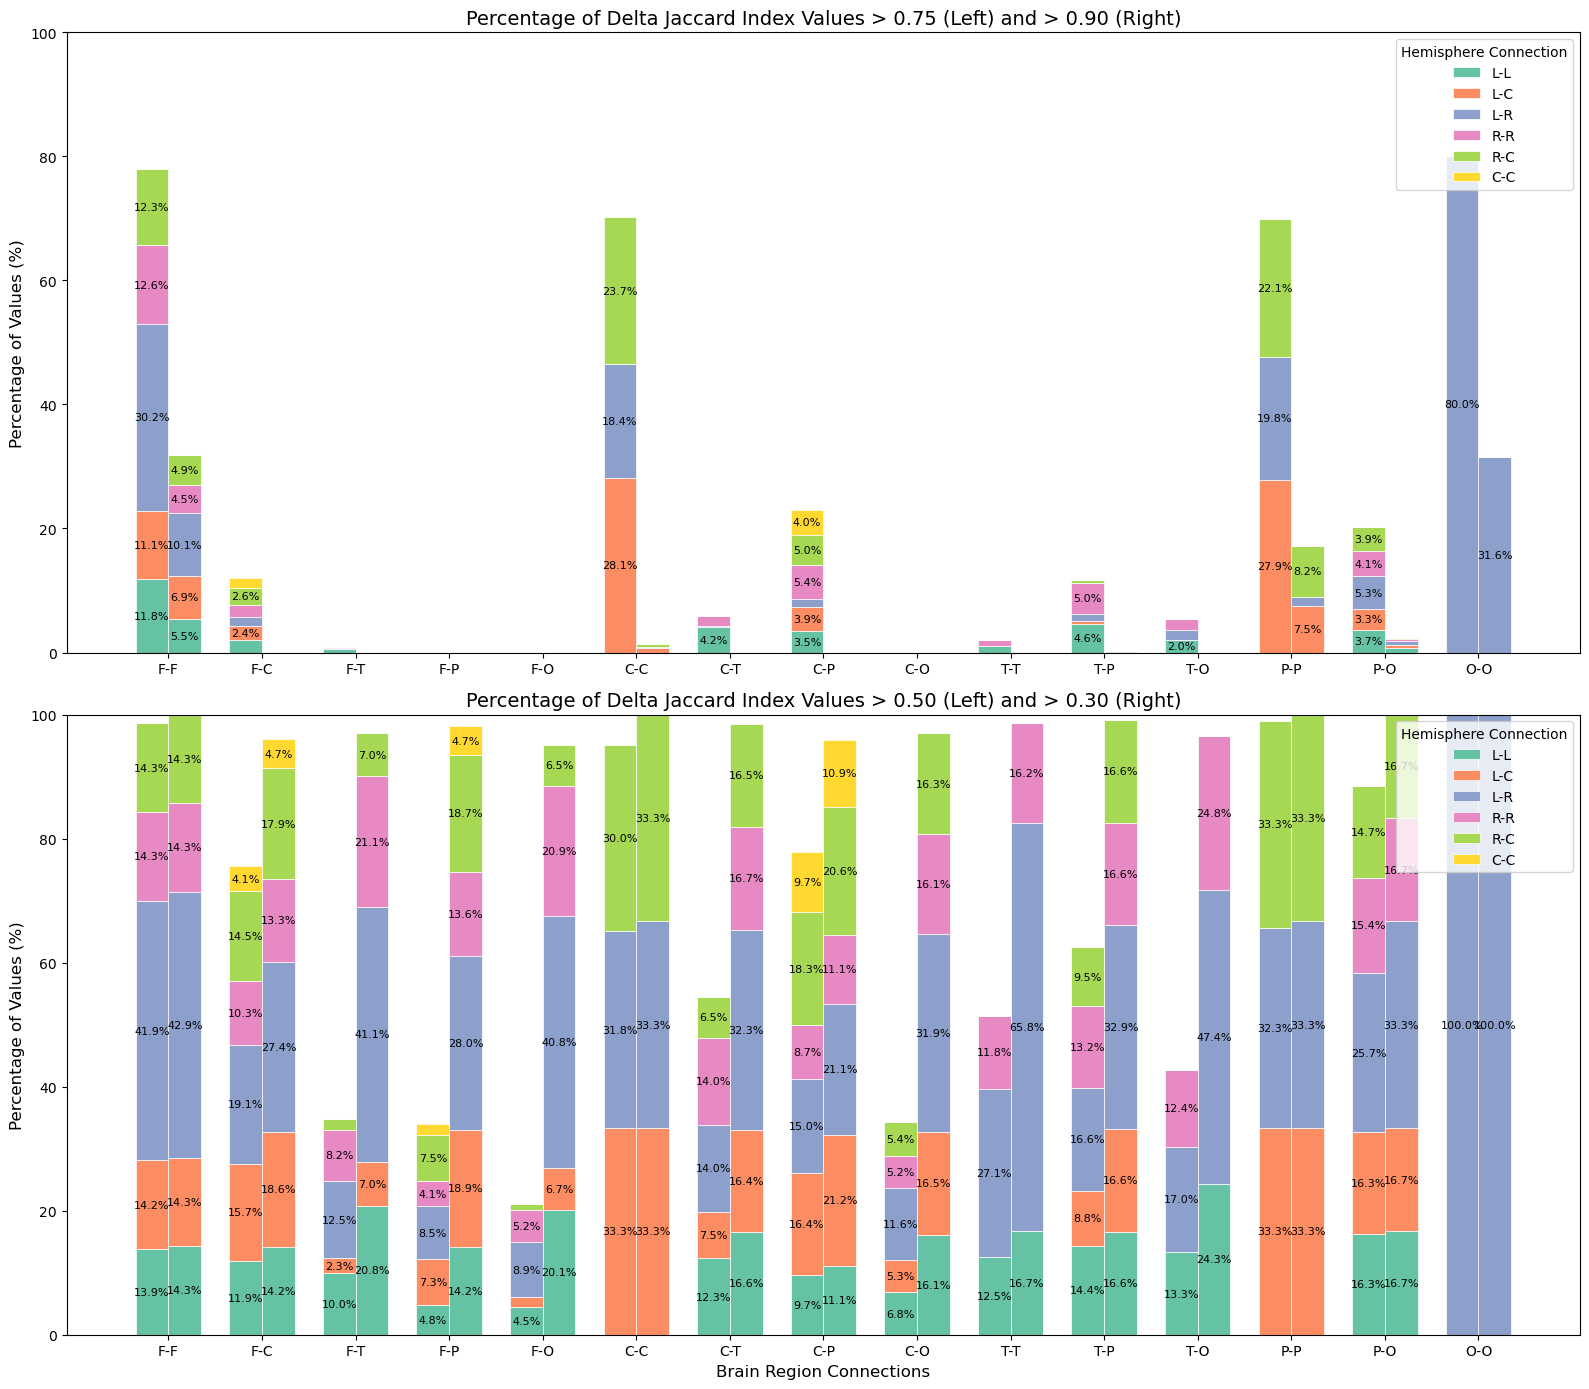

In [7]:
\
# --- 1. Load Hemisphere Labels ---
labels_df = pd.read_csv('../electrode_labels.csv') 
hemi_map = dict(zip(labels_df['channel'], labels_df['label']))

def get_hemi_pair(edge):
    u, v = edge.split('-')
    h1 = hemi_map.get(u, 'C')
    h2 = hemi_map.get(v, 'C')
    
    order = {'L': 0, 'C': 1, 'R': 2}
    if order.get(h1, 99) <= order.get(h2, 99):
        pair = f"{h1}-{h2}"
    else:
        pair = f"{h2}-{h1}"
    
    if pair == 'C-R':
        pair = 'R-C'
    return pair

# --- 2. Define region order and canonical mapping ---
region_order = {'F': 0, 'C': 1, 'T': 2, 'P': 3, 'O': 4}

def get_region_pair(edge):
    u, v = edge.split('-')
    r1, r2 = u[0], v[0]
    if region_order.get(r1, 99) <= region_order.get(r2, 99):
        return f"{r1}-{r2}"
    else:
        return f"{r2}-{r1}"

region_groups = ['F-F', 'F-C', 'F-T', 'F-P', 'F-O',
                 'C-C', 'C-T', 'C-P', 'C-O',
                 'T-T', 'T-P', 'T-O',
                 'P-P', 'P-O',
                 'O-O']

hemi_groups = ['L-L', 'L-C', 'L-R', 'R-R', 'R-C', 'C-C']

# --- 3. Calculate percentages grouped by Region AND Hemisphere ---
stats_data = []

for cat in region_groups:
    edge_indices = [idx for idx, e in enumerate(edge_labels) if get_region_pair(e) == cat]
    total_vals_in_region = len(edge_indices) * heatmap_data.shape[0]
    
    for hemi in hemi_groups:
        hemi_indices = [idx for idx in edge_indices if get_hemi_pair(edge_labels[idx]) == hemi]
        
        if hemi_indices and total_vals_in_region > 0:
            vals = heatmap_data[:, hemi_indices].flatten()
            pct_30 = (np.sum(vals > 0.30) / total_vals_in_region) * 100.0
            pct_50 = (np.sum(vals > 0.50) / total_vals_in_region) * 100.0
            pct_75 = (np.sum(vals > 0.75) / total_vals_in_region) * 100.0
            pct_90 = (np.sum(vals > 0.90) / total_vals_in_region) * 100.0
        else:
            pct_30, pct_50, pct_75, pct_90 = 0.0, 0.0, 0.0, 0.0
            
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.30', 'Hemi': hemi, 'Percentage': pct_30})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.50', 'Hemi': hemi, 'Percentage': pct_50})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.75', 'Hemi': hemi, 'Percentage': pct_75})
        stats_data.append({'Region Pair': cat, 'Threshold': '> 0.90', 'Hemi': hemi, 'Percentage': pct_90})

df_stats = pd.DataFrame(stats_data)

# --- 4. Plot the Stacked Bar Charts ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 14))

colors = sns.color_palette("Set2", 6) 
color_map = dict(zip(hemi_groups, colors))

x = np.arange(len(region_groups))
width = 0.35

def plot_grouped_stacked(ax, thresh1, thresh2, title):
    df1 = df_stats[df_stats['Threshold'] == thresh1].pivot(index='Region Pair', columns='Hemi', values='Percentage')
    df1 = df1.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    df2 = df_stats[df_stats['Threshold'] == thresh2].pivot(index='Region Pair', columns='Hemi', values='Percentage')
    df2 = df2.reindex(index=region_groups, columns=hemi_groups).fillna(0)
    
    bottom1 = np.zeros(len(region_groups))
    bottom2 = np.zeros(len(region_groups))
    
    for hemi in hemi_groups:
        vals1 = df1[hemi].values
        vals2 = df2[hemi].values
        
        bars1 = ax.bar(x - width/2, vals1, width, bottom=bottom1, label=hemi, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        bars2 = ax.bar(x + width/2, vals2, width, bottom=bottom2, color=color_map[hemi], edgecolor='white', linewidth=0.5)
        
        ax.bar_label(bars1, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals1], label_type='center', fontsize=8)
        ax.bar_label(bars2, labels=[f'{v:.1f}%' if v > 2 else '' for v in vals2], label_type='center', fontsize=8)
        
        bottom1 += vals1
        bottom2 += vals2

    ax.set_xticks(x)
    ax.set_xticklabels(region_groups)
    ax.set_title(title, fontsize=14)
    ax.set_ylabel('Percentage of Values (%)', fontsize=12)
    ax.set_ylim(0, 100)
    ax.legend(title='Hemisphere Connection', loc='upper right')

plot_grouped_stacked(ax1, '> 0.75', '> 0.90', 'Percentage of Delta Jaccard Index Values > 0.75 (Left) and > 0.90 (Right)')
plot_grouped_stacked(ax2, '> 0.50', '> 0.30', 'Percentage of Delta Jaccard Index Values > 0.50 (Left) and > 0.30 (Right)')

ax2.set_xlabel('Brain Region Connections', fontsize=12)

plt.tight_layout()
plt.show()
